# Analisis Kepuasan Hidup Komuter dengan K-Means Clustering

**Pertanyaan penelitian:** segmentasi beban perjalanan dan psikologis; trade-off pendapatan dengan keadilan/waktu keluarga; serta perbedaan demografi. Dataset: `data_commuter Raw.csv`; referensi kode: `Data_Kuesioner_Komuter.xlsx`.

Notebook ini membersihkan dan memvalidasi data, melakukan EDA, memilih K melalui visual elbow (rentang K=2?10), lalu tetap menjalankan **K=3 sesuai ketentuan penelitian**. Kualitas cluster dilaporkan dengan Davies?Bouldin Index (DBI; nilai lebih kecil lebih baik). Hasil cluster bersifat eksploratif, bukan label psikologis yang tervalidasi.

## 1. Metode, definisi skala, dan batas interpretasi

- Variabel clustering hanya `E.1?E.3` dan `F.1?F.8`; demografi serta pendapatan sengaja dikeluarkan supaya tidak menentukan cluster sejak awal. Fitur distandardisasi sebelum K-Means.
- Kamus kuesioner menyatakan skala Likert 1?5, umumnya 1 = sangat tidak setuju/tidak mudah/tidak nyaman/tidak adil dan 5 = sangat setuju/mudah/nyaman/adil. Pernyataan F berorientasi masalah: skor lebih tinggi umumnya menunjukkan gangguan lebih berat.
- Khusus `F.6`, kalimatnya negatif: *kepuasan hidup berkurang akibat menjadi komuter*. Maka skor mentah tinggi = lebih tidak puas; digunakan juga skor terbalik `6 - F.6` agar tinggi berarti kepuasan lebih baik. Kolom kategori `Kepuasan Hidup` dianalisis sebagai kategori terpisah tanpa menganggapnya identik dengan F.6.
- `D.4` adalah pendapatan bulanan IDR; `D.5` adalah versi USD. Keduanya bukan dua kompensasi independen. Perbandingan kelompok pendapatan adalah deskriptif dan tidak membuktikan sebab-akibat. Skala Likert diperlakukan numerik untuk ringkasan dan jarak K-Means; ini penyederhanaan analitis.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import davies_bouldin_score

SEED = 42
CSV_PATH = Path("data_commuter Raw.csv")
if not CSV_PATH.exists():
    raise FileNotFoundError(f"File input tidak ditemukan: {CSV_PATH.resolve()}")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", palette="Set2")


In [2]:
df_raw = pd.read_csv(CSV_PATH)
print(f"Ukuran awal: {df_raw.shape[0]} baris x {df_raw.shape[1]} kolom")
display(df_raw.head())
print("\nTipe data:")
display(df_raw.dtypes.rename("dtype").to_frame())


Ukuran awal: 384 baris x 30 kolom
   No. Responden  A.1  A.2  A.3  A.4  A.5  A.6  B.1  B.2  C.1  C.2  C.3   C.4  D.1  D.2  D.3      D.4     D.5  E.1  E.2  E.3  F.1  F.2  F.3  F.4  F.5  F.6  F.7  F.8     Kepuasan Hidup
0              1    1   30    1    3    1    1    4    4    1    1    2  2.00    4    4    4  2500000  178.57    4    4    5    4    3    4    4    4    3    3    3  Sangat Tidak Puas
1              2    1   40    1    3    1    5    4    5    2    2    4  2.00    4    4    5  1200000   85.71    4    5    4    4    3    4    4    5    4    4    5  Sangat Tidak Puas
2              3    1   38    1    3    1    5    4    4    1    2    3  3.00    3    4    5  1600000  114.29    4    4    5    5    4    4    3    3    3    3    4  Sangat Tidak Puas
3              4    1   27    2    3    1    5    5    4    2    2    4  2.00    4    4    5  1500000  107.14    4    5    4    4    5    5    4    3    4    5    4  Sangat Tidak Puas
4              5    2   28    2    3    1    5

## 2. Pembersihan dan validasi

Pembersihan mengecek nama kolom, duplikasi baris/ID, konversi numerik, nilai kosong, rentang skala Likert dan nilai pendapatan. ID responden bukan fitur analisis. Bila data memuat respons kosong atau di luar rentang, notebook menghentikan analisis dengan pesan yang jelas agar keputusan imputasi/koreksi tidak dilakukan diam-diam. Dataset yang diamati memiliki 384 responden, tidak ada nilai kosong, dan tidak ada duplikasi baris/ID sehingga tidak perlu menghapus atau mengimputasi respons.

In [3]:
likert_cols = [f"{prefix}.{i}" for prefix, stop in [("E", 3), ("F", 8)] for i in range(1, stop + 1)]
required_cols = ["No. Responden", "A.1", "A.2", "A.3", "D.2", "D.4", "D.5", *likert_cols, "Kepuasan Hidup"]
missing_cols = sorted(set(required_cols) - set(df_raw.columns))
if missing_cols:
    raise ValueError(f"Kolom penting tidak tersedia: {missing_cols}")

clean = df_raw.copy()
duplicate_rows = int(clean.duplicated().sum())
if duplicate_rows:
    clean = clean.drop_duplicates().copy()
duplicate_ids = int(clean["No. Responden"].duplicated().sum())
if duplicate_ids:
    raise ValueError(f"Ditemukan {duplicate_ids} ID responden duplikat; perlu pemeriksaan sebelum memilih rekaman.")

numeric_cols = [c for c in required_cols if c != "Kepuasan Hidup"]
for col in numeric_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")
missing_by_col = clean[required_cols].isna().sum()
if missing_by_col.any():
    raise ValueError("Nilai kosong/konversi gagal ditemukan; tentukan penanganan sebelum clustering:\n" + missing_by_col[missing_by_col.gt(0)].to_string())

invalid_likert = {c: int((~clean[c].between(1, 5)).sum()) for c in likert_cols}
invalid_likert = {c: n for c, n in invalid_likert.items() if n}
if invalid_likert:
    raise ValueError(f"Nilai di luar skala Likert 1-5: {invalid_likert}")
if (clean[["D.4", "D.5"]] < 0).any().any():
    raise ValueError("Pendapatan negatif ditemukan; periksa data sumber.")

clean["Jenis Kelamin"] = clean["A.1"].map({1: "Laki-laki", 2: "Perempuan"}).fillna(clean["A.1"].map(lambda v: f"Kode {v} (cek kamus)"))
clean["Status Pernikahan"] = clean["A.3"].map({1: "Menikah", 2: "Belum menikah", 3: "Duda", 4: "Janda"}).fillna(clean["A.3"].map(lambda v: f"Kode {v} (cek kamus)"))
clean["F6_kepuasan_terbalik"] = 6 - clean["F.6"]
clean["Kepuasan Hidup"] = clean["Kepuasan Hidup"].astype("string").str.strip()

quality = pd.DataFrame({
    "Metrik": ["Baris awal", "Baris setelah pembersihan duplikat identik", "Duplikat baris terhapus", "Duplikat ID", "Kolom dengan missing", "Seluruh respons Likert di rentang 1-5"],
    "Nilai": [len(df_raw), len(clean), duplicate_rows, duplicate_ids, int(missing_by_col.gt(0).sum()), not bool(invalid_likert)]
})
display(quality)
print("Label kategori yang ditemukan:", sorted(clean["Kepuasan Hidup"].dropna().unique().tolist()))


                                       Metrik Nilai
0                                  Baris awal   384
1  Baris setelah pembersihan duplikat identik   384
2                     Duplikat baris terhapus     0
3                                 Duplikat ID     0
4                        Kolom dengan missing     0
5       Seluruh respons Likert di rentang 1-5  True
Label kategori yang ditemukan: ['Biasa', 'Sangat Puas', 'Sangat Tidak Puas']


In [4]:
# Simpan salinan bersih tanpa mengubah file sumber.
CLEAN_PATH = Path("data_commuter_clean.csv")
clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8-sig")
print(f"Dataset bersih tersimpan: {CLEAN_PATH.resolve()} ({len(clean)} baris)")


Dataset bersih tersimpan: D:\Document\Excel\Dataset Komuter\data_commuter_clean.csv (384 baris)


## 3. Peta variabel dan EDA

Kode pertanyaan dan deskripsi berikut ditranskripsikan dari `Data_Kuesioner_Komuter.xlsx`. Label kategori untuk gender dan status perkawinan digunakan jika tercantum; kode yang tidak dipetakan tetap ditampilkan sebagai kode agar tidak salah klasifikasi.

In [5]:
variable_guide = pd.DataFrame([
    ("A.1", "Jenis kelamin", "1 laki-laki; 2 perempuan"),
    ("A.2", "Usia (tahun)", "Rasio"),
    ("A.3", "Status pernikahan", "1 menikah; 2 belum menikah; 3 duda; 4 janda"),
    ("D.2", "Penghasilan sebagai komuter itu layak", "Likert 1-5; persetujuan"),
    ("D.4 / D.5", "Pendapatan per bulan", "IDR / USD; mata uang alternatif"),
    ("E.1", "Kemudahan moda transportasi", "Likert 1-5; tinggi lebih mudah"),
    ("E.2", "Kenyamanan perjalanan ke lokasi kerja", "Likert 1-5; tinggi lebih nyaman"),
    ("E.3", "Keadilan waktu tempuh ke lokasi kerja", "Likert 1-5; tinggi lebih adil"),
    ("F.1", "Hidup lebih baik tanpa menjadi penglaju", "Likert 1-5; tinggi lebih setuju"),
    ("F.2", "Kurang waktu interaksi sosial", "Likert 1-5; tinggi = gangguan lebih besar"),
    ("F.3", "Kualitas sebagai orang tua terganggu", "Likert 1-5; tinggi = gangguan lebih besar"),
    ("F.4", "Tidak punya waktu untuk diri sendiri", "Likert 1-5; tinggi = gangguan lebih besar"),
    ("F.5", "Kehidupan keluarga/pasangan terganggu", "Likert 1-5; tinggi = gangguan lebih besar"),
    ("F.6", "Kepuasan hidup berkurang", "Pernyataan negatif; dibalik untuk skor kepuasan"),
    ("F.7", "Stres akibat aktivitas sebagai komuter", "Likert 1-5; tinggi = stres lebih besar"),
    ("F.8", "Perjalanan pulang-pergi membuat kewalahan", "Likert 1-5; tinggi = kewalahan lebih besar"),
], columns=["Kode", "Makna ringkas", "Catatan skala"])
display(variable_guide)


         Kode                              Makna ringkas                                    Catatan skala
0         A.1                              Jenis kelamin                         1 laki-laki; 2 perempuan
1         A.2                               Usia (tahun)                                            Rasio
2         A.3                          Status pernikahan      1 menikah; 2 belum menikah; 3 duda; 4 janda
3         D.2      Penghasilan sebagai komuter itu layak                          Likert 1-5; persetujuan
4   D.4 / D.5                       Pendapatan per bulan                  IDR / USD; mata uang alternatif
5         E.1                Kemudahan moda transportasi                   Likert 1-5; tinggi lebih mudah
6         E.2      Kenyamanan perjalanan ke lokasi kerja                  Likert 1-5; tinggi lebih nyaman
7         E.3      Keadilan waktu tempuh ke lokasi kerja                    Likert 1-5; tinggi lebih adil
8         F.1    Hidup lebih baik tanpa menjad

In [6]:
print("Ringkasan numerik:")
display(clean.select_dtypes(include="number").describe().T.round(2))
print("\nFrekuensi kategori penting:")
for col in ["Jenis Kelamin", "Status Pernikahan", "Kepuasan Hidup"]:
    display(clean[col].value_counts(dropna=False).rename_axis(col).to_frame("n"))


Ringkasan numerik:
                      count        mean         std        min         25%         50%         75%          max
No. Responden         384.0      192.50      111.00       1.00       96.75      192.50      288.25       384.00
A.1                   384.0        1.26        0.44       1.00        1.00        1.00        2.00         2.00
A.2                   384.0       35.17        9.12      18.00       28.00       35.00       40.00        56.00
A.3                   384.0        1.32        0.65       1.00        1.00        1.00        1.00         5.00
A.4                   384.0        3.27        1.02       1.00        3.00        3.00        4.00         6.00
A.5                   384.0        1.08        0.47       1.00        1.00        1.00        1.00         5.00
A.6                   384.0        3.52        1.40       1.00        3.00        4.00        5.00         5.00
B.1                   384.0        3.93        0.68       2.00        4.00        4.0

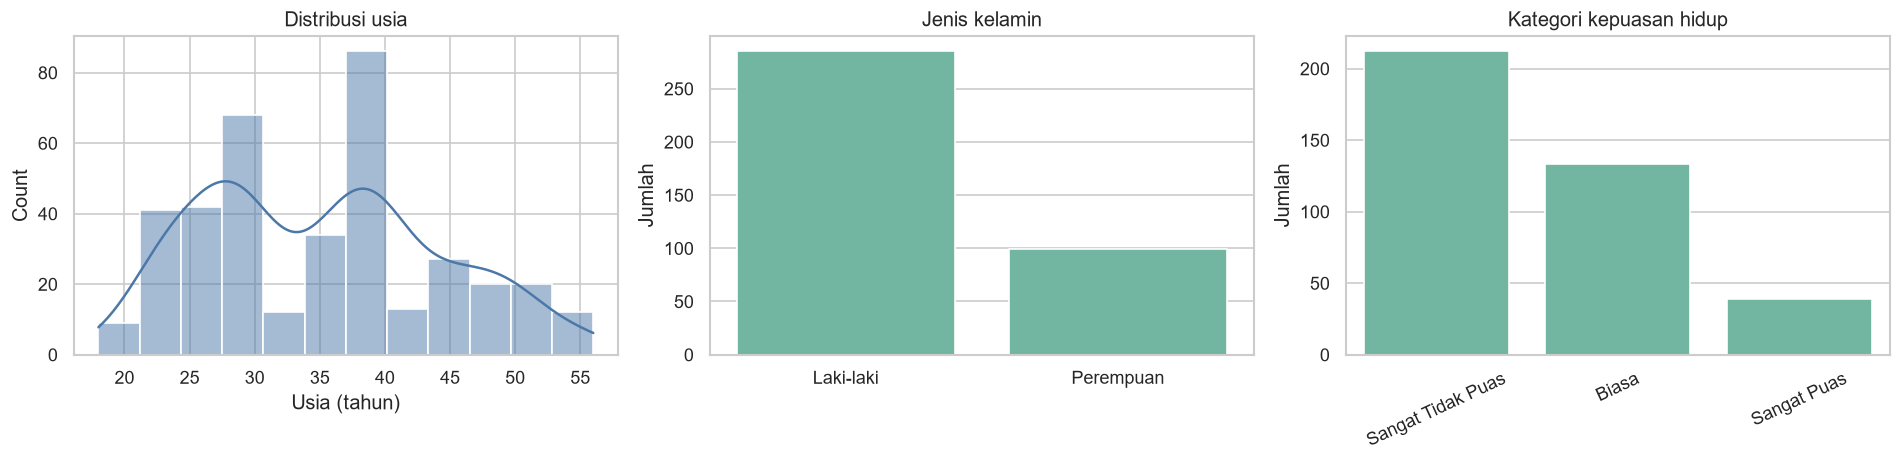

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(clean["A.2"], bins=12, kde=True, ax=axes[0], color="#4C78A8")
axes[0].set(title="Distribusi usia", xlabel="Usia (tahun)")
sns.countplot(data=clean, x="Jenis Kelamin", order=clean["Jenis Kelamin"].value_counts().index, ax=axes[1])
axes[1].set(title="Jenis kelamin", xlabel="", ylabel="Jumlah")
sns.countplot(data=clean, x="Kepuasan Hidup", order=clean["Kepuasan Hidup"].value_counts().index, ax=axes[2])
axes[2].set(title="Kategori kepuasan hidup", xlabel="", ylabel="Jumlah")
axes[2].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


     Rata-rata
F.5       3.19
F.3       3.20
F.4       3.22
F.2       3.23
F.6       3.27
F.7       3.33
F.8       3.37
F.1       3.51
E.3       3.80
E.2       3.82
E.1       3.95


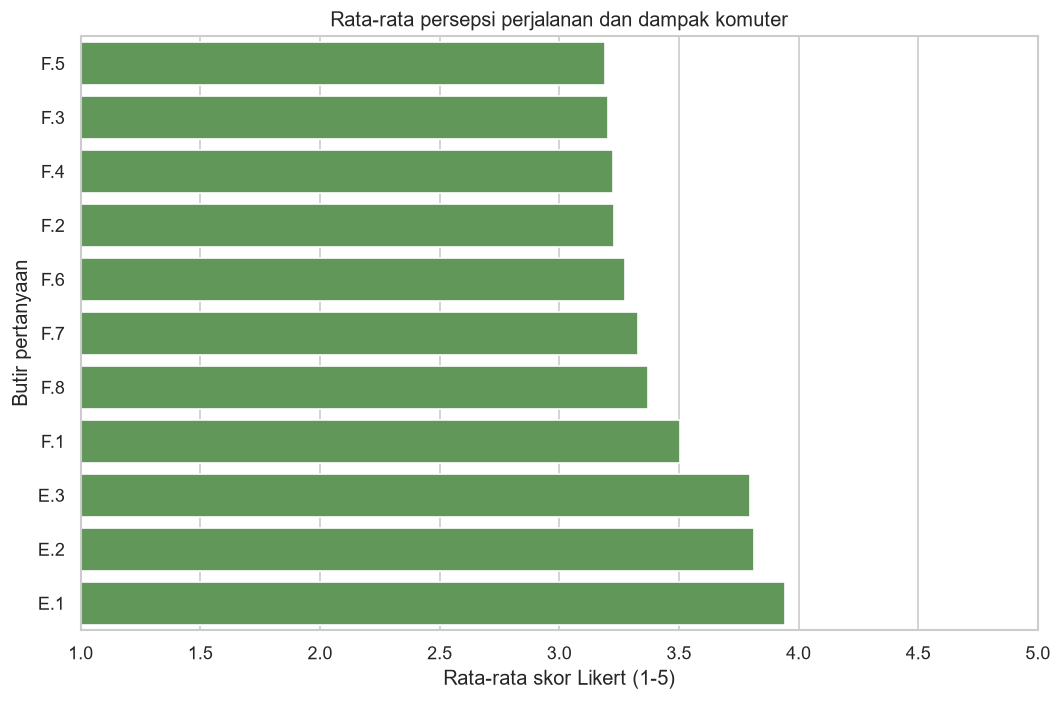

In [8]:
likert_means = clean[likert_cols].mean().sort_values()
plt.figure(figsize=(9, 6))
sns.barplot(x=likert_means.values, y=likert_means.index, color="#59A14F")
plt.xlim(1, 5)
plt.xlabel("Rata-rata skor Likert (1-5)")
plt.ylabel("Butir pertanyaan")
plt.title("Rata-rata persepsi perjalanan dan dampak komuter")
plt.tight_layout()
plt.show()
display(likert_means.rename("Rata-rata").to_frame().round(2))


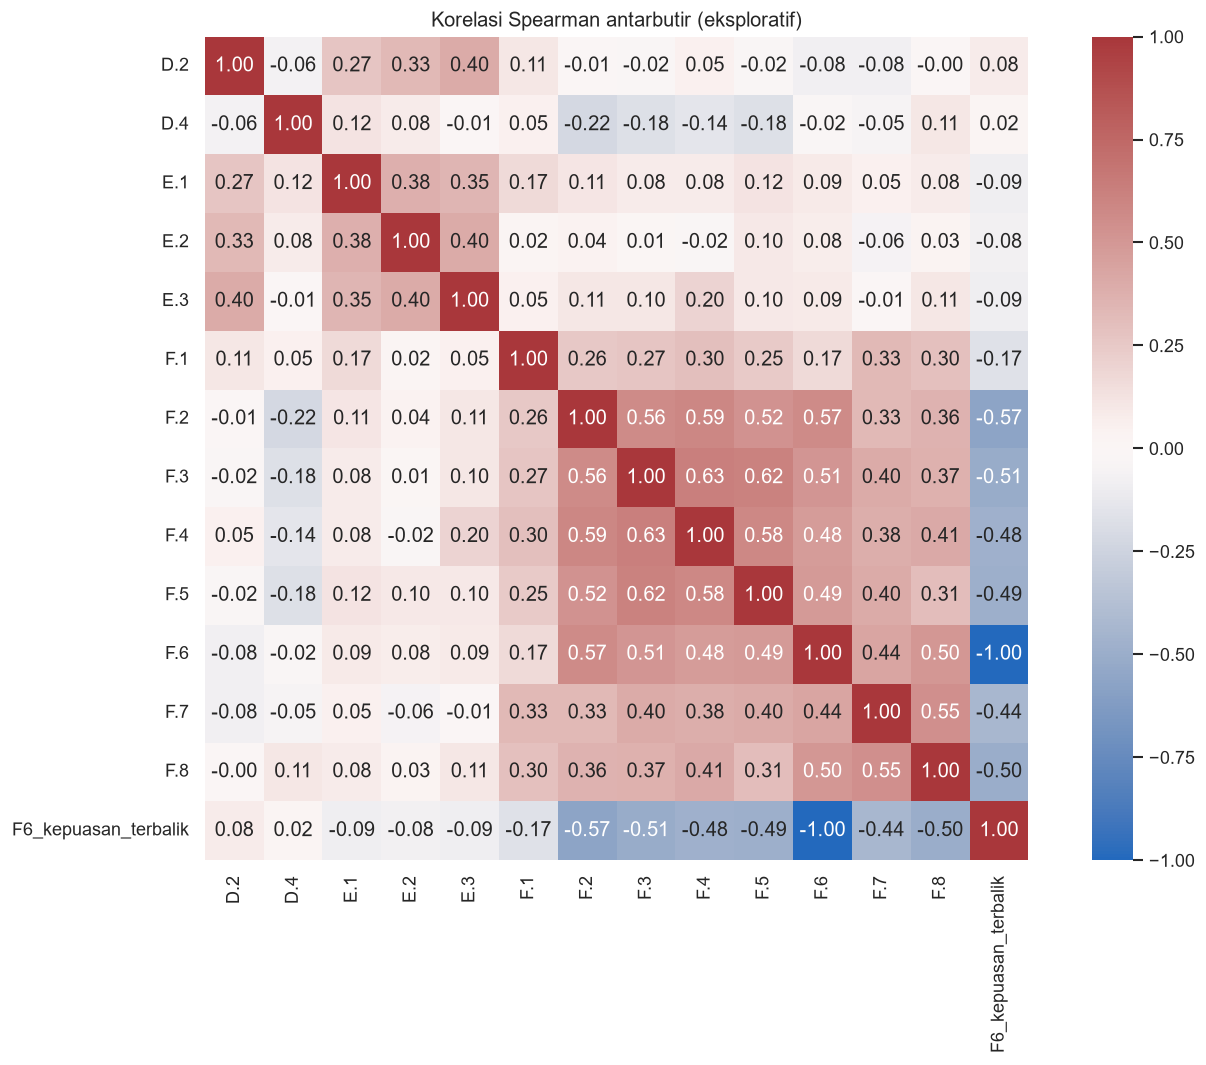

In [9]:
eda_corr_cols = ["D.2", "D.4", "E.1", "E.2", "E.3", *[f"F.{i}" for i in range(1, 9)], "F6_kepuasan_terbalik"]
plt.figure(figsize=(12, 9))
sns.heatmap(clean[eda_corr_cols].corr(method="spearman"), cmap="vlag", center=0, annot=True, fmt=".2f", square=True)
plt.title("Korelasi Spearman antarbutir (eksploratif)")
plt.tight_layout()
plt.show()


## 4. Segmentasi K-Means: elbow, K=3, dan Davies?Bouldin

Elbow ditampilkan pada rentang K=2?10 untuk melihat pengurangan inertia. Karena jumlah cluster penelitian sudah ditetapkan tiga, model akhir tetap memakai K=3?elbow bukan satu-satunya dasar pemilihan. DBI dihitung pada fitur yang sudah distandardisasi; semakin rendah nilainya, semakin kompak dan terpisah cluster secara relatif.

    K  Inertia
0   2  3183.07
1   3  2743.44
2   4  2526.68
3   5  2363.40
4   6  2247.16
5   7  2161.80
6   8  2099.03
7   9  1999.15
8  10  1948.87


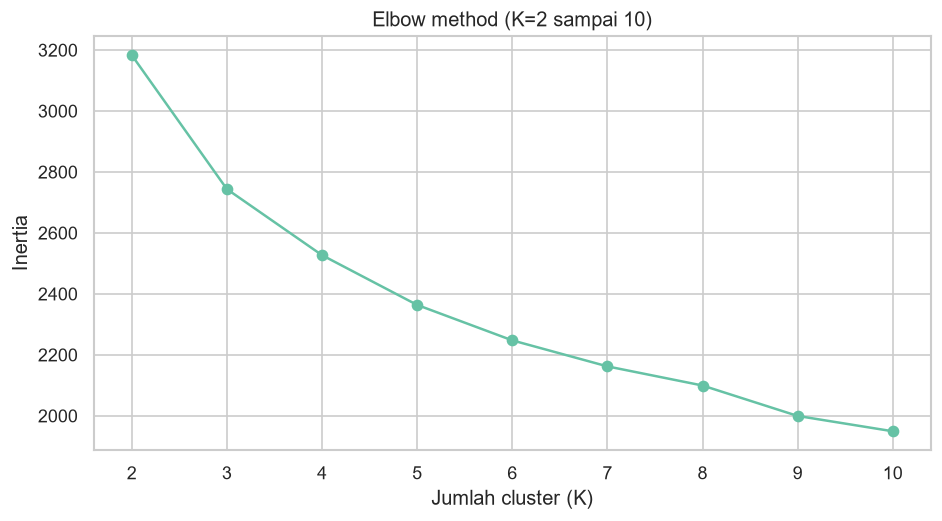

In [10]:
cluster_features = [f"E.{i}" for i in range(1, 4)] + [f"F.{i}" for i in range(1, 9)]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(clean[cluster_features])
elbow_rows = []
for k in range(2, 11):
    model_k = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    model_k.fit(X_scaled)
    elbow_rows.append({"K": k, "Inertia": model_k.inertia_})
elbow = pd.DataFrame(elbow_rows)
plt.figure(figsize=(8, 4.5))
plt.plot(elbow["K"], elbow["Inertia"], marker="o")
plt.xticks(elbow["K"])
plt.xlabel("Jumlah cluster (K)")
plt.ylabel("Inertia")
plt.title("Elbow method (K=2 sampai 10)")
plt.tight_layout()
plt.show()
display(elbow.round(2))


In [11]:
FINAL_K = 3
kmeans = KMeans(n_clusters=FINAL_K, random_state=SEED, n_init=20)
clean["Cluster"] = kmeans.fit_predict(X_scaled)
dbi = davies_bouldin_score(X_scaled, clean["Cluster"])
cluster_counts = clean["Cluster"].value_counts().sort_index()
print(f"K final = {FINAL_K}; Davies-Bouldin Index = {dbi:.3f} (lebih kecil relatif lebih baik)")
display(cluster_counts.rename("Jumlah responden").to_frame().assign(Persentase=(cluster_counts / len(clean) * 100).round(1)))


K final = 3; Davies-Bouldin Index = 1.840 (lebih kecil relatif lebih baik)
         Jumlah responden  Persentase
Cluster                              
0                     131        34.1
1                     157        40.9
2                      96        25.0


In [12]:
cluster_means = clean.groupby("Cluster")[cluster_features].mean()
cluster_profiles = cluster_means.copy()
cluster_profiles["Rata-rata tekanan psikologis"] = clean.groupby("Cluster")[[f"F.{i}" for i in [1, 2, 3, 4, 5, 7, 8]]].mean().mean(axis=1)
cluster_profiles["Rata-rata kenyamanan/persepsi transportasi"] = clean.groupby("Cluster")[["E.1", "E.2", "E.3"]].mean().mean(axis=1)
cluster_profiles["n"] = cluster_counts

# Nama persona mengikuti posisi relatif rata-rata tekanan dan kualitas transportasi pada hasil K-Means ini.
burden = cluster_profiles["Rata-rata tekanan psikologis"]
comfort = cluster_profiles["Rata-rata kenyamanan/persepsi transportasi"]
ordered_burden = burden.sort_values()
labels = {}
for rank, cluster_id in enumerate(ordered_burden.index):
    if rank == 0:
        labels[cluster_id] = "Relatif santai / tekanan rendah"
    elif rank == len(ordered_burden) - 1:
        labels[cluster_id] = "Tekanan dan gangguan waktu tinggi"
    else:
        labels[cluster_id] = "Profil menengah / perlu dicermati"
cluster_profiles["Persona sementara"] = pd.Series(labels)
print("Rata-rata pusat cluster pada skala asli 1-5 (bukan centroid standardized):")
display(cluster_profiles.round(2))


Rata-rata pusat cluster pada skala asli 1-5 (bukan centroid standardized):
          E.1   E.2   E.3   F.1   F.2   F.3   F.4   F.5   F.6   F.7   F.8  Rata-rata tekanan psikologis  Rata-rata kenyamanan/persepsi transportasi    n                  Persona sementara
Cluster                                                                                                                                                                                    
0        4.16  4.01  4.12  3.89  3.89  3.95  3.97  3.91  3.94  3.88  3.92                          3.91                                        4.10  131  Tekanan dan gangguan waktu tinggi
1        3.68  3.48  3.41  3.43  3.17  3.15  3.11  3.03  3.21  3.34  3.37                          3.23                                        3.52  157  Profil menengah / perlu dicermati
2        4.09  4.09  3.99  3.10  2.42  2.27  2.39  2.48  2.47  2.57  2.62                          2.55                                        4.06   96    Relatif santai / 

In [13]:
profile_demo = clean.groupby("Cluster").agg(
    n=("No. Responden", "size"), usia_rata2=("A.2", "mean"), pendapatan_IDR_median=("D.4", "median"),
    penghasilan_layak_D2=("D.2", "mean"), kepuasan_F6_terbalik=("F6_kepuasan_terbalik", "mean"),
    puas_sangat_puas_proporsi=("Kepuasan Hidup", lambda s: s.eq("Sangat Puas").mean())
)
print("Profil demografi dan ekonomi menurut cluster (fitur ini tidak dipakai membentuk cluster):")
display(profile_demo.round(2))
print("\nKomposisi jenis kelamin per cluster (% baris):")
display(pd.crosstab(clean["Cluster"], clean["Jenis Kelamin"], normalize="index").mul(100).round(1))


Profil demografi dan ekonomi menurut cluster (fitur ini tidak dipakai membentuk cluster):
           n  usia_rata2  pendapatan_IDR_median  penghasilan_layak_D2  kepuasan_F6_terbalik  puas_sangat_puas_proporsi
Cluster                                                                                                               
0        131       32.21              1800000.0                  3.92                  2.06                       0.01
1        157       34.90              1900000.0                  3.52                  2.79                       0.06
2         96       39.65              2000000.0                  4.11                  3.53                       0.29

Komposisi jenis kelamin per cluster (% baris):
Jenis Kelamin  Laki-laki  Perempuan
Cluster                            
0                   71.0       29.0
1                   74.5       25.5
2                   78.1       21.9


## 5. Analisis pertanyaan penelitian

### 5.1 Apakah komuter berpendapatan tinggi paling banyak mengorbankan waktu sosial/keluarga?

Pendapatan dibagi menjadi tiga kelompok berdasarkan kuantil D.4; bila banyak nilai sama, pembagian quantile dapat menghasilkan kelompok lebih sedikit. Skor F.2/F.3/F.5 yang lebih tinggi berarti gangguan waktu lebih besar. Tabel juga membandingkan indikator tersebut per cluster.

In [14]:
income_labels = ["Pendapatan rendah", "Pendapatan menengah", "Pendapatan tinggi"]
try:
    clean["Kelompok Pendapatan"] = pd.qcut(clean["D.4"], q=3, labels=income_labels, duplicates="drop")
except ValueError as exc:
    raise ValueError(f"Tidak dapat membentuk kelompok pendapatan berbasis kuantil: {exc}")
family_items = ["F.2", "F.3", "F.5"]
income_family = clean.groupby("Kelompok Pendapatan", observed=True).agg(
    n=("No. Responden", "size"), D4_median_IDR=("D.4", "median"), **{f"{c}_mean": (c, "mean") for c in family_items}
)
income_family["Rata-rata F2-F3-F5"] = income_family[[f"{c}_mean" for c in family_items]].mean(axis=1)
display(income_family.round(2))
cluster_family = clean.groupby("Cluster").agg(
    n=("No. Responden", "size"), D4_median_IDR=("D.4", "median"), **{f"{c}_mean": (c, "mean") for c in family_items}
)
display(cluster_family.round(2))
low_key, high_key = income_family.index[0], income_family.index[-1]
low_score = income_family.loc[low_key, "Rata-rata F2-F3-F5"]
high_score = income_family.loc[high_key, "Rata-rata F2-F3-F5"]
print(f"Selisih (tinggi - rendah) pada rerata gangguan sosial/keluarga = {high_score-low_score:+.2f} poin. Nilai positif berarti kelompok tinggi melaporkan gangguan lebih besar.")


                       n  D4_median_IDR  F.2_mean  F.3_mean  F.5_mean  Rata-rata F2-F3-F5
Kelompok Pendapatan                                                                      
Pendapatan rendah    143      1400000.0      3.42      3.39      3.32                3.38
Pendapatan menengah  140      2000000.0      3.19      3.25      3.25                3.23
Pendapatan tinggi    101      3000000.0      3.02      2.87      2.92                2.94
           n  D4_median_IDR  F.2_mean  F.3_mean  F.5_mean
Cluster                                                  
0        131      1800000.0      3.89      3.95      3.91
1        157      1900000.0      3.17      3.15      3.03
2         96      2000000.0      2.42      2.27      2.48
Selisih (tinggi - rendah) pada rerata gangguan sosial/keluarga = -0.44 poin. Nilai positif berarti kelompok tinggi melaporkan gangguan lebih besar.


### 5.2 Trade-off finansial vs psikologis

`D.2` mengukur apakah penghasilan sebagai komuter dirasa layak (bukan pendapatan rupiah). D.4/D.5 menggambarkan jumlah pendapatan, sedangkan E.3 dan F.8 mengukur persepsi keadilan waktu tempuh dan rasa kewalahan. Analisis berikut memisahkan nominal pendapatan dari persepsi kelayakan, serta melaporkan korelasi Spearman sebagai asosiasi monotonic.

In [15]:
income_tradeoff = clean.groupby("Kelompok Pendapatan", observed=True).agg(
    n=("No. Responden", "size"), pendapatan_IDR_median=("D.4", "median"), D2_layak_mean=("D.2", "mean"),
    E3_keadilan_mean=("E.3", "mean"), F8_kewalahan_mean=("F.8", "mean")
)
display(income_tradeoff.round(2))
adequacy = clean.groupby("D.2").agg(n=("No. Responden", "size"), pendapatan_IDR_median=("D.4", "median"), E3_mean=("E.3", "mean"), F8_mean=("F.8", "mean"))
display(adequacy.round(2))
tradeoff_corr = clean[["D.4", "D.2", "E.3", "F.8"]].corr(method="spearman").loc[["D.4", "D.2"], ["E.3", "F.8"]]
print("Korelasi Spearman (pendapatan nominal D.4 / persepsi kelayakan D.2 vs E.3/F.8):")
display(tradeoff_corr.round(3))


                       n  pendapatan_IDR_median  D2_layak_mean  E3_keadilan_mean  F8_kewalahan_mean
Kelompok Pendapatan                                                                                
Pendapatan rendah    143              1400000.0           3.81              3.81               3.25
Pendapatan menengah  140              2000000.0           3.85              3.81               3.42
Pendapatan tinggi    101              3000000.0           3.73              3.75               3.47
       n  pendapatan_IDR_median  E3_mean  F8_mean
D.2                                              
2      6              1500000.0     3.50     2.67
3    101              2000000.0     3.35     3.32
4    239              2000000.0     3.95     3.47
5     38              2000000.0     4.11     2.97
Korelasi Spearman (pendapatan nominal D.4 / persepsi kelayakan D.2 vs E.3/F.8):
       E.3    F.8
D.4 -0.011  0.107
D.2  0.401 -0.005


### 5.3 Apakah merasa penghasilan layak terkait kepuasan hidup, walau waktu diri berkurang?

F.4 yang tinggi berarti waktu untuk diri sendiri dirasa kurang. F.6 mentah yang tinggi berarti kepuasan hidup *berkurang* lebih kuat; skor balik F6 lebih tinggi berarti kepuasan yang lebih baik. Tabel `Kepuasan Hidup` adalah kategori sumber, sehingga perbandingan disajikan berdampingan dan bukan dipaksakan sebagai satu skala.

In [16]:
adequacy_satisfaction = clean.groupby("D.2").agg(
    n=("No. Responden", "size"), F4_tidak_ada_waktu_diri=("F.4", "mean"),
    F6_mentah_kepuasan_berkurang=("F.6", "mean"), F6_skor_kepuasan_terbalik=("F6_kepuasan_terbalik", "mean")
)
display(adequacy_satisfaction.round(2))
print("Distribusi kategori Kepuasan Hidup menurut persepsi kelayakan D.2 (% dalam tiap skor D.2):")
display(pd.crosstab(clean["D.2"], clean["Kepuasan Hidup"], normalize="index").mul(100).round(1))
print("Korelasi Spearman D.2 dengan F.4, F.6 mentah, dan F6 terbalik:")
display(clean[["D.2", "F.4", "F.6", "F6_kepuasan_terbalik"]].corr(method="spearman").loc[["D.2"], ["F.4", "F.6", "F6_kepuasan_terbalik"]].round(3))


       n  F4_tidak_ada_waktu_diri  F6_mentah_kepuasan_berkurang  F6_skor_kepuasan_terbalik
D.2                                                                                       
2      6                     2.67                          3.00                       3.00
3    101                     3.13                          3.32                       2.68
4    239                     3.30                          3.32                       2.68
5     38                     3.11                          2.92                       3.08
Distribusi kategori Kepuasan Hidup menurut persepsi kelayakan D.2 (% dalam tiap skor D.2):
Kepuasan Hidup  Biasa  Sangat Puas  Sangat Tidak Puas
D.2                                                  
2                66.7         16.7               16.7
3                52.5          5.0               42.6
4                26.4         12.6               61.1
5                34.2          7.9               57.9
Korelasi Spearman D.2 dengan F.4, F.6 m

### 5.4 Interaksi anak/pasangan menurut gender dan status pernikahan

F.3/F.5 diringkas untuk gabungan gender ? status perkawinan. Nilai sampel kecil ditandai dengan `n`; subkelompok berisi sedikit responden tidak layak dijadikan kesimpulan populasi. Untuk menjawab contoh pertanyaan secara lebih langsung, tabel kedua membatasi status menikah dan membandingkan gender.

In [17]:
family_by_demo = clean.groupby(["Jenis Kelamin", "Status Pernikahan"], observed=True).agg(
    n=("No. Responden", "size"), F3_gangguan_anak_mean=("F.3", "mean"), F5_gangguan_pasangan_mean=("F.5", "mean")
).sort_values("n", ascending=False)
display(family_by_demo.round(2))
married = clean[clean["A.3"].eq(1)]
married_gender = married.groupby("Jenis Kelamin").agg(
    n=("No. Responden", "size"), F3_mean=("F.3", "mean"), F5_mean=("F.5", "mean")
)
display(married_gender.round(2))
if {"Laki-laki", "Perempuan"}.issubset(married_gender.index):
    print("Selisih perempuan - laki-laki menikah:", (married_gender.loc["Perempuan", ["F3_mean", "F5_mean"]] - married_gender.loc["Laki-laki", ["F3_mean", "F5_mean"]]).round(2).to_dict())


                                    n  F3_gangguan_anak_mean  F5_gangguan_pasangan_mean
Jenis Kelamin Status Pernikahan                                                        
Laki-laki     Menikah             232                   3.06                       3.06
Perempuan     Menikah              57                   3.39                       3.40
Laki-laki     Belum menikah        49                   3.51                       3.45
Perempuan     Belum menikah        32                   3.44                       3.34
              Janda                10                   3.00                       3.00
Laki-laki     Duda                  3                   3.67                       3.67
              Kode 5 (cek kamus)    1                   3.00                       3.00
                 n  F3_mean  F5_mean
Jenis Kelamin                       
Laki-laki      232     3.06     3.06
Perempuan       57     3.39     3.40
Selisih perempuan - laki-laki menikah: {'F3_mean': 0.32, 'F5

### 5.5 Kelompok usia yang paling setuju hidup lebih baik tanpa menjadi penglaju

F.1 yang tinggi berarti lebih setuju dengan pernyataan tersebut. Rentang dibentuk dengan batas 18?24, 25?34, 35?44, dan 45+ tahun; kelompok dengan rerata tertinggi dilaporkan bersama ukuran sampelnya.

In [18]:
age_bins = [17, 24, 34, 44, np.inf]
age_labels = ["18-24", "25-34", "35-44", "45+"]
clean["Kelompok Usia"] = pd.cut(clean["A.2"], bins=age_bins, labels=age_labels, include_lowest=True)
age_f1 = clean.groupby("Kelompok Usia", observed=False).agg(n=("No. Responden", "size"), F1_mean=("F.1", "mean"))
display(age_f1.round(2))
valid_age = age_f1[age_f1["n"].gt(0)]
peak_age = valid_age["F1_mean"].idxmax()
print(f"Rerata F.1 tertinggi: kelompok {peak_age}, mean={valid_age.loc[peak_age, 'F1_mean']:.2f}, n={int(valid_age.loc[peak_age, 'n'])}.")


                 n  F1_mean
Kelompok Usia              
18-24           50     3.50
25-34          127     3.54
35-44          130     3.56
45+             77     3.35
Rerata F.1 tertinggi: kelompok 35-44, mean=3.56, n=130.


## 6. Ringkasan temuan otomatis dari data

Pernyataan di bawah dihasilkan dari hasil hitung di atas agar kesimpulan selalu mengikuti dataset/notebook yang sedang dijalankan. Perbedaan kecil tidak otomatis berarti perbedaan yang signifikan secara statistik.

In [19]:
high_burden_id = burden.idxmax()
low_burden_id = burden.idxmin()
hi_cl = cluster_profiles.loc[high_burden_id]
lo_cl = cluster_profiles.loc[low_burden_id]
print(f"1) Segmentasi K=3: DBI={dbi:.3f}; ukuran cluster={cluster_counts.to_dict()}.")
for cid in sorted(cluster_counts.index):
    r = cluster_profiles.loc[cid]
    d = profile_demo.loc[cid]
    print(f"   Cluster {cid} ({int(r['n'])} responden): {r['Persona sementara']}; E rata-rata={r['Rata-rata kenyamanan/persepsi transportasi']:.2f}, tekanan F={r['Rata-rata tekanan psikologis']:.2f}; usia rata-rata={d['usia_rata2']:.1f} tahun; median pendapatan={d['pendapatan_IDR_median']:,.0f} IDR.")
print(f"   Cluster tekanan tertinggi (ID {high_burden_id}) tetap memiliki E tinggi ({hi_cl['Rata-rata kenyamanan/persepsi transportasi']:.2f}) tetapi tekanan F {hi_cl['Rata-rata tekanan psikologis']:.2f}; cluster tekanan terendah (ID {low_burden_id}) E={lo_cl['Rata-rata kenyamanan/persepsi transportasi']:.2f}, tekanan F={lo_cl['Rata-rata tekanan psikologis']:.2f}.")
print(f"2) Pengorbanan sosial/keluarga: rerata F2/F3/F5 kelompok pendapatan tinggi={high_score:.2f}, rendah={low_score:.2f}; selisih tinggi-rendah={high_score-low_score:+.2f} poin. Rincian (tinggi vs rendah): " + ", ".join(f"{c} {income_family.loc[high_key, f'{c}_mean']:.2f} vs {income_family.loc[low_key, f'{c}_mean']:.2f}" for c in family_items) + f". Klaim pendapatan tinggi paling terdampak {'didukung secara deskriptif' if high_score>low_score else 'tidak didukung oleh rerata kelompok pada dataset ini'}.")
print(f"3) Trade-off nominal: kelompok D4 tinggi vs rendah memiliki E.3 {income_tradeoff.loc[high_key, 'E3_keadilan_mean']:.2f} vs {income_tradeoff.loc[low_key, 'E3_keadilan_mean']:.2f}, dan F.8 {income_tradeoff.loc[high_key, 'F8_kewalahan_mean']:.2f} vs {income_tradeoff.loc[low_key, 'F8_kewalahan_mean']:.2f}. rho Spearman D4-E3={clean['D.4'].corr(clean['E.3'], method='spearman'):.2f}; D4-F8={clean['D.4'].corr(clean['F.8'], method='spearman'):.2f}. Tidak ada bukti deskriptif bahwa nominal pendapatan menutupi persepsi waktu/perjalanan.")
if 5 in adequacy_satisfaction.index:
    d2best = adequacy_satisfaction.loc[5]
    print(f"4) D2=5 (n={int(d2best['n'])}): skor kepuasan F6 terbalik={d2best['F6_skor_kepuasan_terbalik']:.2f}/5, tetapi F4 kurang waktu diri={d2best['F4_tidak_ada_waktu_diri']:.2f}/5. D2=4 (n={int(adequacy_satisfaction.loc[4, 'n'])}) masing-masing {adequacy_satisfaction.loc[4, 'F6_skor_kepuasan_terbalik']:.2f} dan {adequacy_satisfaction.loc[4, 'F4_tidak_ada_waktu_diri']:.2f}. Kepuasan kategori sumber terbanyak: {clean['Kepuasan Hidup'].value_counts().index[0]} (n={clean['Kepuasan Hidup'].value_counts().iloc[0]}).")
print("5) Pada responden menikah, rerata dan n F3/F5 per gender:")
print(married_gender.round(2).to_string())
if {"Laki-laki", "Perempuan"}.issubset(married_gender.index):
    diff = married_gender.loc["Perempuan", ["F3_mean", "F5_mean"]] - married_gender.loc["Laki-laki", ["F3_mean", "F5_mean"]]
    print(f"   Selisih perempuan-laki-laki menikah: F3={diff['F3_mean']:+.2f}, F5={diff['F5_mean']:+.2f}; sampel {int(married_gender.loc['Perempuan','n'])} vs {int(married_gender.loc['Laki-laki','n'])}.")
print(f"6) Rerata F.1 tertinggi terdapat pada usia {peak_age} (n={int(valid_age.loc[peak_age, 'n'])}, mean={valid_age.loc[peak_age, 'F1_mean']:.2f}/5).")

1) Segmentasi K=3: DBI=1.840; ukuran cluster={0: 131, 1: 157, 2: 96}.
   Cluster 0 (131 responden): Tekanan dan gangguan waktu tinggi; E rata-rata=4.10, tekanan F=3.91; usia rata-rata=32.2 tahun; median pendapatan=1,800,000 IDR.
   Cluster 1 (157 responden): Profil menengah / perlu dicermati; E rata-rata=3.52, tekanan F=3.23; usia rata-rata=34.9 tahun; median pendapatan=1,900,000 IDR.
   Cluster 2 (96 responden): Relatif santai / tekanan rendah; E rata-rata=4.06, tekanan F=2.55; usia rata-rata=39.6 tahun; median pendapatan=2,000,000 IDR.
   Cluster tekanan tertinggi (ID 0) tetap memiliki E tinggi (4.10) tetapi tekanan F 3.91; cluster tekanan terendah (ID 2) E=4.06, tekanan F=2.55.
2) Pengorbanan sosial/keluarga: rerata F2/F3/F5 kelompok pendapatan tinggi=2.94, rendah=3.38; selisih tinggi-rendah=-0.44 poin. Rincian (tinggi vs rendah): F.2 3.02 vs 3.42, F.3 2.87 vs 3.39, F.5 2.92 vs 3.32. Klaim pendapatan tinggi paling terdampak tidak didukung oleh rerata kelompok pada dataset ini.
3) Tr

## 7. Kesimpulan dan keterbatasan

Gunakan tabel persona dan ringkasan otomatis sebagai jawaban inti, lalu jelaskan pola spesifik dari tabel pendapatan, D.2, demografi, dan usia. Beberapa batas penting:

1. K-Means mengasumsikan jarak Euclidean; standardisasi mencegah skala tertentu mendominasi, tetapi perlakuan Likert sebagai jarak numerik tetap asumsi.
2. DBI dan elbow mengukur aspek internal cluster saja. DBI bukan ukuran validitas konstruk; K=3 dipertahankan sesuai rancangan penelitian, walaupun elbow dapat tampak tidak tegas.
3. Label persona bersifat ringkasan interpretatif dari rerata cluster, bukan hasil diagnosis. Komposisi cluster bisa berubah dengan sampel/seed/model.
4. Analisis kelompok dan korelasi bersifat deskriptif, tanpa kontrol perancu dan tanpa uji inferensial; tidak menunjukkan pengaruh sebab-akibat. Tampilkan n dan hindari generalisasi pada subkelompok sangat kecil.
5. Kategori `Kepuasan Hidup` dibandingkan secara terpisah dari butir F.6 karena hubungan pengkodeannya tidak dijelaskan dalam kamus yang tersedia.
6. Temuan hanya mewakili responden dalam file, bukan otomatis semua komuter. Pendapatan nominal juga tidak mengukur biaya hidup, jam kerja, maupun daya beli.